# Signal Preprocessing and Noise Handling

## Component 4: Multi-Sensor Machine Learning-Based Road Roughness Assessment and Cross-Vehicle-Driver Generalization

This notebook converts the synchronized PVS1–PVS9 datasets (Notebook 01) into clean, noise-handled signals and analysis windows. Each step addresses a noise source identified in Notebook 02, Section 10.

| Noise source | Characteristic | Handling |
|---|---|---|
| Unit inconsistency | gyroscope in deg/s | all signals converted to SI units (m/s², rad/s, m/s) |
| Missing data / timestamp gaps | – | short gaps interpolated, longer gaps start a new segment; filters never run across a gap |
| Sensor glitches | full-scale (saturated) readings | replaced by a 5-sample median; the Hampel filter is computed as a diagnostic only, because statistical outliers on bad roads are genuine impacts (Section 4) |
| Gravity, bias, slow drift | < 0.3 Hz | gravity vector estimated with a 0.3 Hz low-pass and subtracted |
| Electronic high-frequency noise | close to Nyquist (50 Hz) | 4th-order Butterworth 40 Hz low-pass, zero-phase |
| Sensor orientation | gravity split differently over axes | orientation-invariant channels: vertical, horizontal, magnitude, gyroscope magnitude |
| Stops and crawling | no road excitation | windows below 1 m/s excluded (thresholds applied in Notebook 05) |
| Speed bumps | road furniture, not roughness | windows containing speed-bump labels excluded |
| Driver manoeuvres | turning, braking, accelerating | lateral and longitudinal acceleration computed per window (used in Notebook 05) |
| Vehicle/engine vibration | present without road input | stationary windows collected here; noise profile subtracted in Notebook 04 |

**Processing order:** unit harmonisation → cleaning and segmentation → glitch replacement → gravity/drift removal → low-pass filtering → orientation-invariant channels → windowing. Glitches are replaced first because a filter would spread a glitch over its neighbours. All filters are zero-phase (`sosfiltfilt`), so no time shift is introduced between sensors and labels.

**Sensors:** accelerometer and gyroscope of all six IMUs (left/right × dashboard, above suspension, below suspension). Magnetometer and temperature are not used (Notebook 02, Section 10.4).

**Outputs** (in `MyDrive/PVS_Processed`): processed signals per dataset, the window table, and the configuration used.

In [21]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

## 1. Configuration
All preprocessing parameters are defined in `c4.CFG`. They can be changed here; the values are then saved so that Notebooks 04–09 use exactly the same configuration.

In [23]:
# Optional changes, for example:
# c4.CFG['WINDOW_SEC'] = 2.0
# c4.CFG['LABEL_MODE'] = 'worst'      # road_condition from Notebook 01 (worst of left and right)

keys = ['FS', 'WINDOW_SEC', 'STEP_SEC', 'LABEL_MODE', 'MIN_PURITY', 'MIN_SPEED', 'STOP_SPEED', 'GRAVITY_HZ',
        'LOWPASS_HZ', 'HAMPEL_HALF', 'HAMPEL_K', 'HAMPEL_MAX_RUN', 'LAT_ACC_MAX', 'LONG_ACC_MAX']
display(pd.Series({k: c4.CFG[k] for k in keys}, name='value').to_frame())
print('Window:', c4.win_len(), 'samples | step:', c4.step_len(), 'samples | sensors:', c4.SENSORS)
c4.save_config()

,value
FS,100.0
WINDOW_SEC,2.0
STEP_SEC,1.0
LABEL_MODE,worst
MIN_PURITY,0.8
MIN_SPEED,1.0
STOP_SPEED,0.3
GRAVITY_HZ,0.3
LOWPASS_HZ,40.0
HAMPEL_HALF,2


Window: 200 samples | step: 100 samples | sensors: ['left_dashboard', 'left_above_suspension', 'left_below_suspension', 'right_dashboard', 'right_above_suspension', 'right_below_suspension']
Configuration saved -> /content/drive/MyDrive/PVS_Processed/config_used.json


## 2. Unit harmonisation
Units are detected from PVS1 and applied identically to all datasets.

In [24]:
UNITS = c4.detect_units(c4.load_trip(1))
print('Detected units:', {k: v for k, v in UNITS.items() if k != 'evidence'})
print('Evidence      :', UNITS['evidence'])
print('-> acceleration ~9.8 at rest means m/s²; gyroscope values above 3 mean deg/s; speed p95 below 35 means m/s')

Detected units: {'acc': 'm/s2', 'gyro': 'deg/s', 'speed': 'm/s'}
Evidence      : {'acc_median_norm': 9.831, 'gyro_p99_5': 20.692, 'speed_p95': 24.121}
-> acceleration ~9.8 at rest means m/s²; gyroscope values above 3 mean deg/s; speed p95 below 35 means m/s


## 3. Cleaning, noise handling and windowing for PVS1–PVS9

In [25]:
import time
reports, windows, spike_rows, examples = [], [], [], {}
t0 = time.time()
for n in range(1, 10):
    df = c4.harmonise_units(c4.load_trip(n), UNITS)
    df, rep = c4.clean_trip(df)
    RAW, PROC, SPIKE, YAW, LONG = c4.process_trip(df)
    A_n, stat = c4.make_windows(df, YAW, LONG)
    c4.save_trip(n, RAW, PROC, SPIKE, stat, df)
    windows.append(A_n)
    reports.append({'Dataset': f'PVS{n}', 'Vehicle': c4.PVS_META[n][0], **rep,
                    'windows': len(A_n), 'stationary windows': len(stat)})
    lab = df['label'].values
    for k, s in enumerate(c4.SENSORS):
        for ci, cname in enumerate(c4.CLASSES):
            m = lab == ci
            spike_rows.append({'pvs': n, 'vehicle': c4.PVS_META[n][0], 'sensor': s, 'class': cname,
                               'replaced %': 100 * SPIKE[m, k].mean() if m.any() else np.nan})
    if n == 1:   # keep a short example for plots
        examples = {'df': df.iloc[:].reset_index(drop=True), 'RAW': RAW, 'PROC': PROC}
    print(f'PVS{n}: {rep["rows_out"]:,} rows, {rep["segments"]} segment(s), {len(A_n):,} windows '
          f'({time.time() - t0:.0f}s)')

A = pd.concat(windows, ignore_index=True)
A.to_parquet(os.path.join(c4.PROCESSED_DIR, 'windows.parquet'), index=False)
cleaning_report = pd.DataFrame(reports)
cleaning_report.to_csv(os.path.join(c4.PROCESSED_DIR, 'cleaning_report.csv'), index=False)
display(cleaning_report)

PVS1: 144,036 rows, 1 segment(s), 1,439 windows (11s)
PVS2: 124,684 rows, 1 segment(s), 1,245 windows (20s)
PVS3: 105,816 rows, 1 segment(s), 1,057 windows (29s)
PVS4: 132,492 rows, 1 segment(s), 1,323 windows (39s)
PVS5: 133,877 rows, 1 segment(s), 1,337 windows (55s)
PVS6: 96,279 rows, 1 segment(s), 961 windows (61s)
PVS7: 128,548 rows, 1 segment(s), 1,284 windows (73s)
PVS8: 123,618 rows, 1 segment(s), 1,235 windows (81s)
PVS9: 91,555 rows, 1 segment(s), 914 windows (90s)


,Dataset,Vehicle,rows_in,duplicates,gaps,bad_rows,rows_out,segments,windows,stationary windows
0,PVS1,VW Saveiro,144036,0,0,0,144036,1,1439,60
1,PVS2,VW Saveiro,124684,0,0,0,124684,1,1245,25
2,PVS3,VW Saveiro,105816,0,0,0,105816,1,1057,46
3,PVS4,Fiat Bravo,132492,0,0,0,132492,1,1323,27
4,PVS5,Fiat Bravo,133877,0,0,0,133877,1,1337,26
5,PVS6,Fiat Bravo,96279,0,0,0,96279,1,961,23
6,PVS7,Fiat Palio,128548,0,0,0,128548,1,1284,33
7,PVS8,Fiat Palio,123618,0,0,0,123618,1,1235,31
8,PVS9,Fiat Palio,91555,0,0,0,91555,1,914,19


## 4. Evidence: statistical outliers are road events, not noise
The Hampel filter flags samples that deviate strongly from their local median. If these flags were sensor glitches, their share would be **small and similar across road classes**. If they are genuine impacts (potholes, cracks), the share is **clearly higher on Bad roads**.

On the real data the flagged share was about **5 % on Bad roads versus about 0.4 % on Good roads**, and a stricter single-axis rule did not change this pattern. Replacing these samples would therefore remove exactly the vibration that identifies rough roads. The final pipeline keeps all statistical outliers (`HAMPEL_REPLACE = False`) and replaces only full-scale readings (±16 g, ±2000 °/s), which are physically impossible road responses. The table below shows both rates; the Hampel replacement is reported as an evidence-based **rejected configuration**.

In [26]:
spikes = pd.DataFrame(spike_rows)
tab = spikes.groupby(['sensor', 'class'])['replaced %'].mean().unstack()[CL].round(4)
display(tab)
tab.to_csv(os.path.join(c4.PROCESSED_DIR, 'spike_replacement_rate.csv'))

class,good,regular,bad
sensor,,,
left_above_suspension,0.0084,0.0721,0.1211
left_below_suspension,0.3998,3.3511,5.1300
left_dashboard,0.0170,0.5605,0.8650
right_above_suspension,0.0131,0.1686,0.1805
right_below_suspension,0.2020,2.4712,4.6690
right_dashboard,0.0106,0.0492,0.0730


## 5. Evidence: raw and processed signals
The example shows the left dashboard sensor for a Good and a Bad road section of PVS1. The raw vertical axis contains gravity (≈ 9.8 m/s²) and depends on the sensor orientation; the processed vertical acceleration is centred at zero, filtered and orientation-independent.

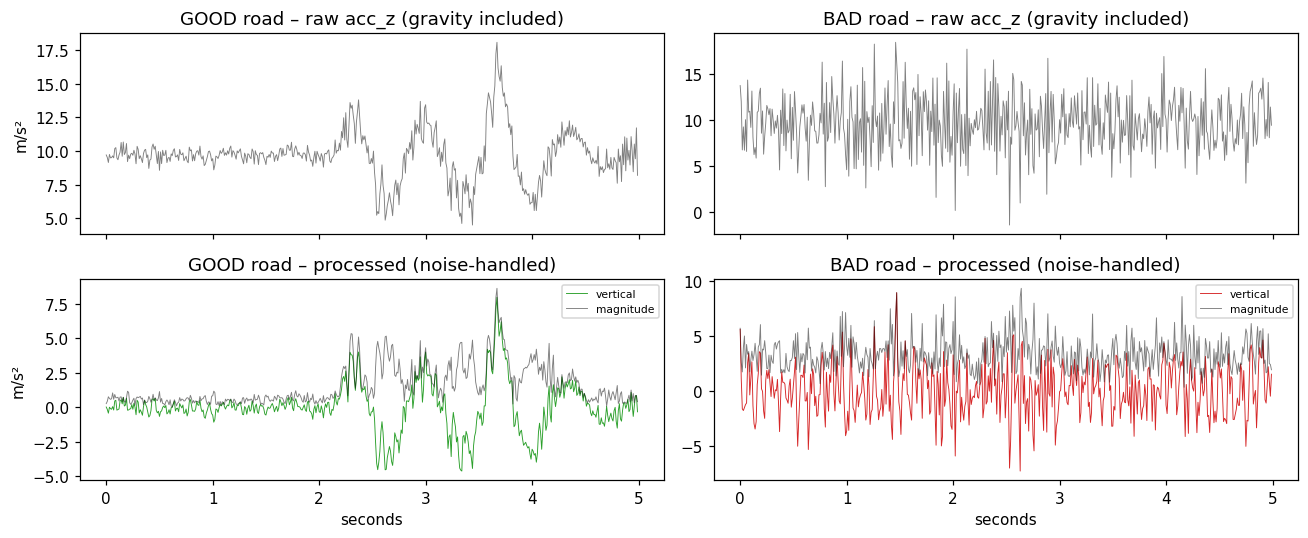

In [27]:
df1, RAW1, PROC1 = examples['df'], examples['RAW'], examples['PROC']
ri = c4.RAW_COLS.index('left_dashboard__acc_z')
pv, pm = c4.PROC_COLS.index('left_dashboard__acc_vert'), c4.PROC_COLS.index('left_dashboard__acc_mag')
fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
for col, cls in enumerate(['good', 'bad']):
    idx = np.where((df1['label'].values == c4.CLASS_ID[cls]) & (df1['speed'].values > 5))[0]
    if len(idx) == 0:
        continue
    s = idx[len(idx) // 2]; sl = slice(s, s + 500)
    t = np.arange(500) / c4.CFG['FS']
    axes[0, col].plot(t, RAW1[sl, ri], lw=.6, c='grey')
    axes[0, col].set_title(f'{cls.upper()} road – raw acc_z (gravity included)')
    axes[1, col].plot(t, PROC1[sl, pv], lw=.6, c=COLORS[cls], label='vertical')
    axes[1, col].plot(t, PROC1[sl, pm], lw=.6, c='k', alpha=.5, label='magnitude')
    axes[1, col].set_title(f'{cls.upper()} road – processed (noise-handled)'); axes[1, col].legend(fontsize=7)
for a in axes[1]: a.set_xlabel('seconds')
for a in axes[:, 0]: a.set_ylabel('m/s²')
plt.tight_layout(); plt.savefig(os.path.join(c4.PROCESSED_DIR, 'raw_vs_processed.png'), dpi=150); plt.show()

## 6. Window table and exclusions

In [28]:
th = c4.CFG
moving = A.speed_mean >= th['MIN_SPEED']
labelled = (A.purity >= th['MIN_PURITY']) & (A.labeled_frac >= th['MIN_LABELED'])
maneuver = (A.lat_acc > th['LAT_ACC_MAX']) | (A.long_acc > th['LONG_ACC_MAX'])
excl = pd.DataFrame({
    'all windows': A.groupby('vehicle').size(),
    'stationary / slow': (~moving).groupby(A.vehicle).sum(),
    'mixed label (purity < min)': (moving & ~labelled).groupby(A.vehicle).sum(),
    'speed bump': (moving & labelled & A.bump).groupby(A.vehicle).sum(),
    'usable labelled': (moving & labelled & ~A.bump).groupby(A.vehicle).sum(),
    'of which manoeuvre': (moving & labelled & ~A.bump & maneuver).groupby(A.vehicle).sum(),
})
display(excl)

,all windows,stationary / slow,mixed label (purity < min),speed bump,usable labelled,of which manoeuvre
vehicle,,,,,,
Fiat Bravo,3621,172,200,79,3170,386
Fiat Palio,3433,182,207,64,2980,336
VW Saveiro,3741,285,259,79,3118,267


## 7. Driver behaviour: manoeuvre statistics
Turning (lateral acceleration = speed × yaw rate) and braking/accelerating (|dv/dt|) produce inertial signals that are not caused by the road. Different drivers produce them at different rates, which makes manoeuvres a **driver-dependent noise source**.

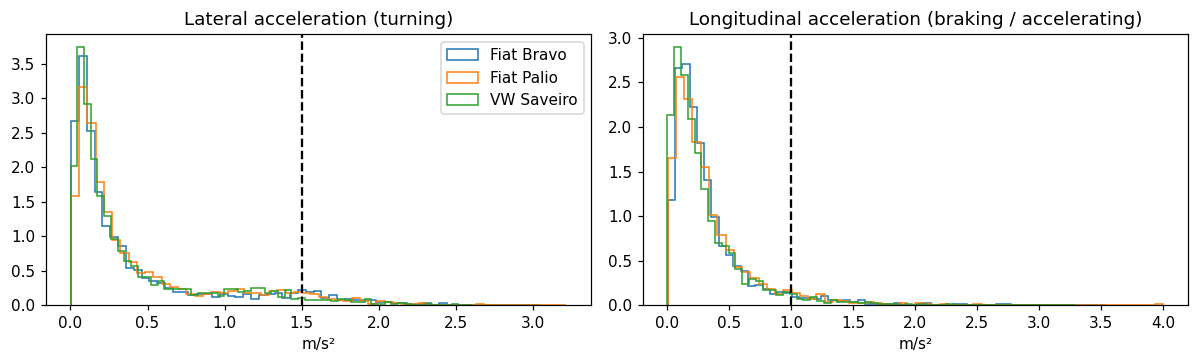

,manoeuvre_pct
vehicle,
Fiat Bravo,12.2
Fiat Palio,11.3
VW Saveiro,8.6


In [29]:
Lw = A[moving & labelled & ~A.bump]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for v, g in Lw.groupby('vehicle'):
    ax[0].hist(g.lat_acc.clip(upper=5), bins=60, histtype='step', density=True, label=v)
    ax[1].hist(g.long_acc.clip(upper=4), bins=60, histtype='step', density=True, label=v)
ax[0].axvline(th['LAT_ACC_MAX'], c='k', ls='--'); ax[1].axvline(th['LONG_ACC_MAX'], c='k', ls='--')
ax[0].set_title('Lateral acceleration (turning)'); ax[1].set_title('Longitudinal acceleration (braking / accelerating)')
for a in ax: a.set_xlabel('m/s²')
ax[0].legend(); plt.tight_layout(); plt.show()
display(Lw.groupby('vehicle').agg(manoeuvre_pct=('lat_acc', lambda s: 100 * ((s > th['LAT_ACC_MAX']) |
        (Lw.loc[s.index, 'long_acc'] > th['LONG_ACC_MAX'])).mean())).round(1))

## 8. Summary
* All nine datasets were converted to SI units, cleaned, segmented at timestamp gaps and processed with full-scale glitch replacement, gravity/drift removal and 40 Hz low-pass filtering.
* Statistical outliers were **kept**: their rate is far higher on Bad roads, so they are road impacts, not noise (Section 4).
* Four orientation-invariant channels were added for every sensor, so the same representation can later be computed on a smartphone with arbitrary orientation.
* Every window stores its speed, label purity, speed-bump flag and manoeuvre indicators. The exclusion thresholds are applied in Notebook 05, so their effect can be examined in the sensitivity analysis (Notebook 07).
* Stationary windows were stored for the vehicle noise profile used in Notebook 04.